<a href="https://colab.research.google.com/github/Keerthan2005-lab/KeerthanDP_BIS/blob/main/Week3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimizing Shuttle Routes using ACO...

Optimization Completed!
Minimum Total Distance: 38.45 units
Total Shuttles/Routes Needed: 3
  Route 1: 0 -> 5 -> 8 -> 1 -> 0 (Passenger Demand Served: 34/40)
  Route 2: 0 -> 2 -> 9 -> 4 -> 7 -> 0 (Passenger Demand Served: 38/40)
  Route 3: 0 -> 6 -> 3 -> 0 (Passenger Demand Served: 32/40)


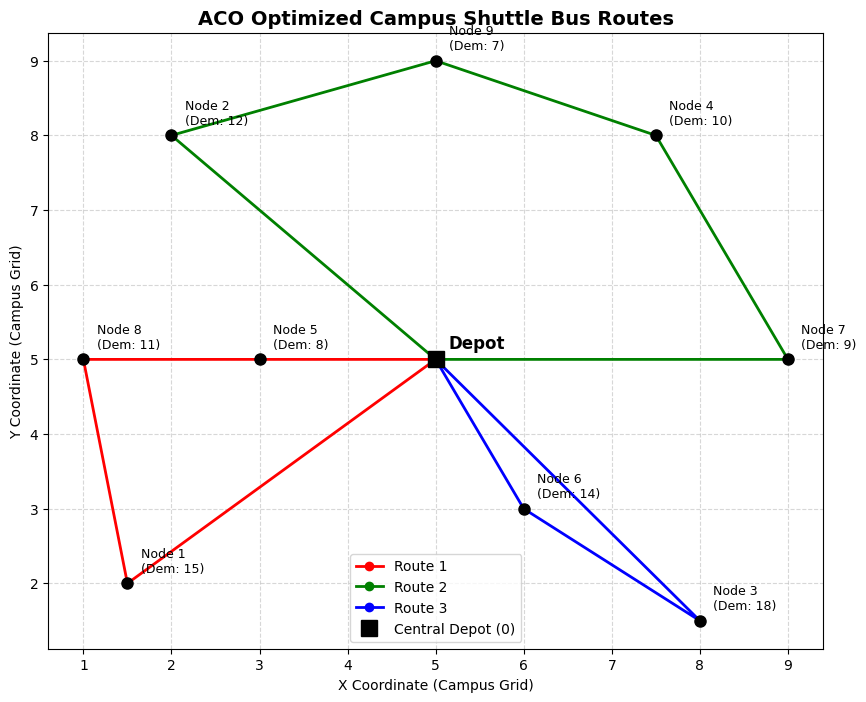

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

# 1. Problem Setup: Campus Locations and Demands
# Nodes: 0 is the Central Depot/Terminal, 1-9 are campus locations (hostels, academic blocks, parking)
num_nodes = 10
vehicle_capacity = 40

# Node coordinates (X, Y) on a campus grid (e.g., in hundreds of meters)
coordinates = {
    0: (5.0, 5.0),   # Depot (Central Terminal)
    1: (1.5, 2.0),   # Hostel Block A
    2: (2.0, 8.0),   # Hostel Block B
    3: (8.0, 1.5),   # Engineering Building
    4: (7.5, 8.0),   # Science Center
    5: (3.0, 5.0),   # Library
    6: (6.0, 3.0),   # Student Union
    7: (9.0, 5.0),   # Sports Complex
    8: (1.0, 5.0),   # Parking West
    9: (5.0, 9.0)    # Parking North
}

# Node Demands (number of passengers waiting to be picked up/dropped off)
demands = {0: 0, 1: 15, 2: 12, 3: 18, 4: 10, 5: 8, 6: 14, 7: 9, 8: 11, 9: 7}

# Calculate Distance Matrix
dist_matrix = np.zeros((num_nodes, num_nodes))
for i in range(num_nodes):
    for j in range(num_nodes):
        if i != j:
            p1, p2 = coordinates[i], coordinates[j]
            dist_matrix[i][j] = np.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)
        else:
            dist_matrix[i][j] = float('inf')

# 2. Ant Colony Optimization (ACO) Parameters
num_ants = 20
num_iterations = 100
alpha = 1.0       # Pheromone importance
beta = 2.0        # Heuristic (1/distance) importance
evaporation_rate = 0.5
Q = 100.0         # Pheromone deposit constant

# Initialize Pheromone Matrix
pheromones = np.ones((num_nodes, num_nodes)) * 0.1

# 3. ACO Algorithm Implementation
best_distance = float('inf')
best_routes = []

def calculate_route_distance(routes):
    total_dist = 0
    for route in routes:
        route_dist = 0
        for i in range(len(route) - 1):
            route_dist += dist_matrix[route[i]][route[i+1]]
        total_dist += route_dist
    return total_dist

print("Optimizing Shuttle Routes using ACO...")

for iteration in range(num_iterations):
    all_ant_routes = []
    all_ant_distances = []

    for ant in range(num_ants):
        unvisited = set(range(1, num_nodes))
        routes = []

        while unvisited:
            route = [0]  # Start at depot
            current_capacity = vehicle_capacity
            curr = 0

            while unvisited:
                # Filter unvisited nodes that satisfy vehicle capacity constraints
                candidates = [node for node in unvisited if demands[node] <= current_capacity]
                if not candidates:
                    break  # Return to depot if capacity is reached or no candidate fits

                # Calculate transition probabilities
                probabilities = []
                for cand in candidates:
                    tau = pheromones[curr][cand] ** alpha
                    eta = (1.0 / dist_matrix[curr][cand]) ** beta
                    probabilities.append(tau * eta)

                prob_sum = sum(probabilities)
                if prob_sum == 0:
                    probabilities = [1.0 / len(candidates)] * len(candidates)
                else:
                    probabilities = [p / prob_sum for p in probabilities]

                # Choose next node
                next_node = np.random.choice(candidates, p=probabilities)
                route.append(next_node)
                current_capacity -= demands[next_node]
                unvisited.remove(next_node)
                curr = next_node

            route.append(0)  # Return to depot
            routes.append(route)

        ant_dist = calculate_route_distance(routes)
        all_ant_routes.append(routes)
        all_ant_distances.append(ant_dist)

        # Update Best Solution
        if ant_dist < best_distance:
            best_distance = ant_dist
            best_routes = routes

    # Pheromone Evaporation
    pheromones *= (1.0 - evaporation_rate)

    # Pheromone Update (Deposit)
    for routes, ant_dist in zip(all_ant_routes, all_ant_distances):
        deposit = Q / ant_dist
        for route in routes:
            for i in range(len(route) - 1):
                pheromones[route[i]][route[i+1]] += deposit
                pheromones[route[i+1]][route[i]] += deposit

# 4. Results Display
print("\nOptimization Completed!")
print(f"Minimum Total Distance: {best_distance:.2f} units")
print(f"Total Shuttles/Routes Needed: {len(best_routes)}")
for idx, route in enumerate(best_routes):
    route_demand = sum(demands[node] for node in route)
    print(f"  Route {idx + 1}: {' -> '.join(map(str, route))} (Passenger Demand Served: {route_demand}/{vehicle_capacity})")

# 5. Visualizing the Optimized Shuttle Routes
plt.figure(figsize=(10, 8))
colors = ['r', 'g', 'b', 'c', 'm', 'y']

# Plot edges/routes
for idx, route in enumerate(best_routes):
    color = colors[idx % len(colors)]
    xs = [coordinates[node][0] for node in route]
    ys = [coordinates[node][1] for node in route]
    plt.plot(xs, ys, marker='o', linestyle='-', linewidth=2, color=color, label=f'Route {idx+1}')

# Plot nodes with demands
for node, (x, y) in coordinates.items():
    if node == 0:
        plt.plot(x, y, 'ks', markersize=12, label='Central Depot (0)')
        plt.text(x + 0.15, y + 0.15, 'Depot', fontsize=12, fontweight='bold')
    else:
        plt.plot(x, y, 'ko', markersize=8)
        plt.text(x + 0.15, y + 0.15, f'Node {node}\n(Dem: {demands[node]})', fontsize=9)

plt.title("ACO Optimized Campus Shuttle Bus Routes", fontsize=14, fontweight='bold')
plt.xlabel("X Coordinate (Campus Grid)")
plt.ylabel("Y Coordinate (Campus Grid)")
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()